# Desafio de Boosting · Aula 7.4

Uma imagem mostra um dígito escrito à mão. O objetivo é prever se ele é **par ou ímpar**. Vamos treinar XGBoost, LightGBM e CatBoost, usar a validação para escolher uma configuração de cada um e comparar as três no mesmo teste.

## 1. Entender o que entra no modelo

Usamos a base `load_digits`, que vem com o scikit-learn. Cada imagem mede 8 × 8 pixels. As 64 intensidades viram as colunas de `X`. Em `y`, a classe **0** significa par e **1** significa ímpar. O modelo recebe os pixels e aprende com esses rótulos.

1797 imagens | 64 pixels por imagem
Faixa de intensidade 0 a 16
Valores ausentes 0


,Imagens
Par,891
Ímpar,906


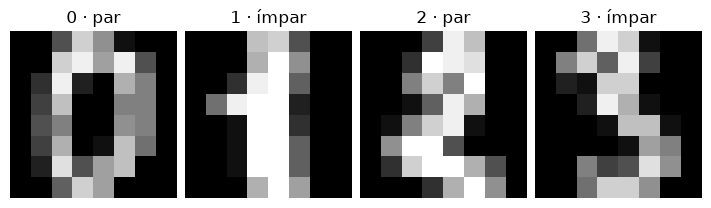

In [1]:
from inspect import signature
from time import perf_counter

import catboost
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score, log_loss,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid, train_test_split

digitos = load_digits()
X = pd.DataFrame(digitos.data, columns=[f"pixel_{i:02d}" for i in range(64)])
y = digitos.target % 2

print(f"{len(X)} imagens | {X.shape[1]} pixels por imagem")
print(f"Faixa de intensidade {X.min().min():g} a {X.max().max():g}")
print(f"Valores ausentes {X.isna().sum().sum()}")
display(pd.Series(y).value_counts().sort_index().rename(index={0: "Par", 1: "Ímpar"}).to_frame("Imagens"))

fig, eixos = plt.subplots(1, 4, figsize=(7, 2.1), layout="constrained")
for ax, numero in zip(eixos, range(4)):
    indice = np.flatnonzero(digitos.target == numero)[0]
    ax.imshow(digitos.images[indice], cmap="gray", vmin=0, vmax=16)
    classe = "par" if y[indice] == 0 else "ímpar"
    ax.set_title(f"{numero} · {classe}")
    ax.axis("off")
plt.show()

## 2. Separar treino, validação e teste

O treino ajusta as árvores. A validação decide quando parar e qual configuração escolher. O teste fica separado para avaliar as três escolhas no final. Usamos aproximadamente 60%, 20% e 20%, mantendo a proporção de pares e ímpares em cada parte.

In [2]:
SEMENTE = 42
LIMIAR = 0.5

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEMENTE,
)

divisao = {
    nome: {"Imagens": len(rotulos), "Pares": (rotulos == 0).sum(),
           "Ímpares": (rotulos == 1).sum()}
    for nome, rotulos in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]
}
display(pd.DataFrame.from_dict(divisao, orient="index"))

,Imagens,Pares,Ímpares
Treino,1077,534,543
Validação,360,179,181
Teste,360,178,182


## 3. Definir o que varia em cada biblioteca

Cada biblioteca testa duas taxas de aprendizado e dois valores de um segundo parâmetro. São quatro combinações por modelo.

| Biblioteca | Segundo parâmetro | O que muda |
|---|---|---|
| XGBoost | `max_depth` | Limita as divisões ao longo de um caminho na árvore. |
| LightGBM | `num_leaves` | Limita quantas folhas a árvore pode ter. |
| CatBoost | `l2_leaf_reg` | Controla a penalização de correções grandes nas folhas. |

Todos podem treinar por até 400 rodadas. A parada antecipada acompanha a **ROC AUC da validação**. Se ela passar 30 rodadas sem melhorar, o treino para. Usamos até quatro threads por modelo.

In [3]:
MAX_RODADAS = 400
PACIENCIA = 30
THREADS = 4

grades = {
    "XGBoost": {"learning_rate": [0.05, 0.10], "max_depth": [3, 5]},
    "LightGBM": {"learning_rate": [0.05, 0.10], "num_leaves": [15, 31]},
    "CatBoost": {"learning_rate": [0.05, 0.10], "l2_leaf_reg": [1.0, 5.0]},
}


def treinar(nome, parametros):
    if nome == "XGBoost":
        modelo = xgboost.XGBClassifier(
            n_estimators=MAX_RODADAS, objective="binary:logistic",
            eval_metric="auc", early_stopping_rounds=PACIENCIA,
            tree_method="hist", n_jobs=THREADS, random_state=SEMENTE, **parametros,
        )
        opcoes = {"eval_set": [(X_val, y_val)], "verbose": False}
    elif nome == "LightGBM":
        modelo = lightgbm.LGBMClassifier(
            n_estimators=MAX_RODADAS, objective="binary", metric="auc",
            n_jobs=THREADS, random_state=SEMENTE, verbosity=-1, **parametros,
        )
        opcoes = {"callbacks": [lightgbm.early_stopping(PACIENCIA, verbose=False)]}
        if "eval_X" in signature(modelo.fit).parameters:
            opcoes.update(eval_X=X_val, eval_y=y_val)
        else:
            opcoes["eval_set"] = [(X_val, y_val)]
    else:
        modelo = catboost.CatBoostClassifier(
            iterations=MAX_RODADAS, depth=5, loss_function="Logloss",
            eval_metric="AUC", thread_count=THREADS, random_seed=SEMENTE,
            allow_writing_files=False, **parametros,
        )
        opcoes = {
            "eval_set": (X_val, y_val), "early_stopping_rounds": PACIENCIA,
            "use_best_model": True, "verbose": False,
        }

    inicio = perf_counter()
    modelo.fit(X_train, y_train, **opcoes)
    return modelo, perf_counter() - inicio


def arvores_usadas(nome, modelo):
    if nome == "XGBoost":
        return modelo.best_iteration + 1
    if nome == "LightGBM":
        return modelo.best_iteration_
    return modelo.tree_count_

## 4. Escolher a configuração pela validação

Treinamos as quatro combinações de cada biblioteca com as mesmas imagens. A ROC AUC mede quão bem o modelo tende a colocar imagens ímpares acima das pares quando ordena suas probabilidades. Guardamos, em cada biblioteca, o modelo com maior ROC AUC na validação.

In [4]:
def probabilidade_impar(modelo, entradas):
    coluna_impar = list(modelo.classes_).index(1)
    return modelo.predict_proba(entradas)[:, coluna_impar]


tentativas = []
melhores = {}
modelos_escolhidos = {}

for nome, grade in grades.items():
    for parametros in ParameterGrid(grade):
        modelo, tempo = treinar(nome, parametros)
        auc = roc_auc_score(y_val, probabilidade_impar(modelo, X_val))
        resultado = {
            "Modelo": nome,
            "Parâmetros variados": ", ".join(f"{k}={v}" for k, v in parametros.items()),
            "ROC AUC validação": auc,
            "Árvores usadas": arvores_usadas(nome, modelo),
            "Tempo (s)": tempo,
        }
        tentativas.append(resultado)
        if nome not in melhores or auc > melhores[nome]["ROC AUC validação"]:
            melhores[nome] = resultado
            modelos_escolhidos[nome] = modelo

tabela_validacao = pd.DataFrame(tentativas)
display(tabela_validacao.round(4))

print("Configurações escolhidas")
display(pd.DataFrame(melhores.values()).set_index("Modelo").round(4))

,Modelo,Parâmetros variados,ROC AUC validação,Árvores usadas,Tempo (s)
0,XGBoost,"learning_rate=0.05, max_depth=3",0.9980,322,0.1729
1,XGBoost,"learning_rate=0.05, max_depth=5",0.9984,299,0.1882
2,XGBoost,"learning_rate=0.1, max_depth=3",0.9975,196,0.1097
3,XGBoost,"learning_rate=0.1, max_depth=5",0.9980,96,0.0790
4,LightGBM,"learning_rate=0.05, num_leaves=15",0.9979,148,0.0767
5,LightGBM,"learning_rate=0.05, num_leaves=31",0.9987,220,0.1157
6,LightGBM,"learning_rate=0.1, num_leaves=15",0.9995,270,0.0790
7,LightGBM,"learning_rate=0.1, num_leaves=31",0.9990,208,0.0893
8,CatBoost,"l2_leaf_reg=1.0, learning_rate=0.05",0.9981,252,0.2501
9,CatBoost,"l2_leaf_reg=1.0, learning_rate=0.1",0.9985,182,0.1484


Configurações escolhidas


,Parâmetros variados,ROC AUC validação,Árvores usadas,Tempo (s)
Modelo,,,,
XGBoost,"learning_rate=0.05, max_depth=5",0.9984,299,0.1882
LightGBM,"learning_rate=0.1, num_leaves=15",0.9995,270,0.0790
CatBoost,"l2_leaf_reg=1.0, learning_rate=0.1",0.9985,182,0.1484


## 5. Comparar os três no teste

Usamos o mesmo limiar, **0,5**, para transformar as probabilidades em classes. Acurácia, precisão, recall e F1 usam essas classes. ROC AUC e log loss usam as probabilidades. Nas matrizes, a diagonal conta os acertos e as outras células mostram os dois tipos de erro.

,Acurácia,Precisão,Recall,F1,ROC AUC,Log Loss,Tempo (s)
Modelo,,,,,,,
XGBoost,0.9861,0.9836,0.9890,0.9863,0.9997,0.0351,0.1882
LightGBM,0.9917,0.9891,0.9945,0.9918,0.9998,0.0225,0.0790
CatBoost,0.9917,0.9891,0.9945,0.9918,0.9995,0.0308,0.1484


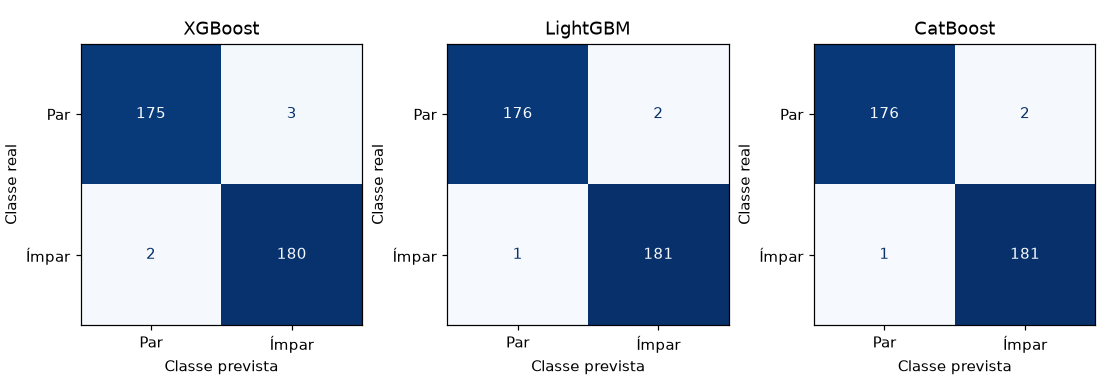

In [5]:
resultados_teste = []
fig, eixos = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")

for ax, (nome, modelo) in zip(eixos, modelos_escolhidos.items()):
    probabilidades = probabilidade_impar(modelo, X_test)
    previsoes = (probabilidades >= LIMIAR).astype(int)
    resultados_teste.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, previsoes),
        "Precisão": precision_score(y_test, previsoes, zero_division=0),
        "Recall": recall_score(y_test, previsoes, zero_division=0),
        "F1": f1_score(y_test, previsoes, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilidades),
        "Log Loss": log_loss(y_test, probabilidades),
        "Tempo (s)": melhores[nome]["Tempo (s)"],
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, previsoes, labels=[0, 1], display_labels=["Par", "Ímpar"],
        ax=ax, cmap="Blues", colorbar=False,
        im_kw={"vmin": 0, "vmax": np.bincount(y_test).max()},
    )
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe real")

tabela_teste = pd.DataFrame(resultados_teste).set_index("Modelo")
display(tabela_teste.round(4))
plt.show()

## 6. Ler os resultados junto com o tempo

A acurácia mostra quantas imagens foram classificadas corretamente. A ROC AUC mostra como as probabilidades ordenaram as duas classes. Os tempos são das configurações escolhidas, medidos durante o treino desta execução.

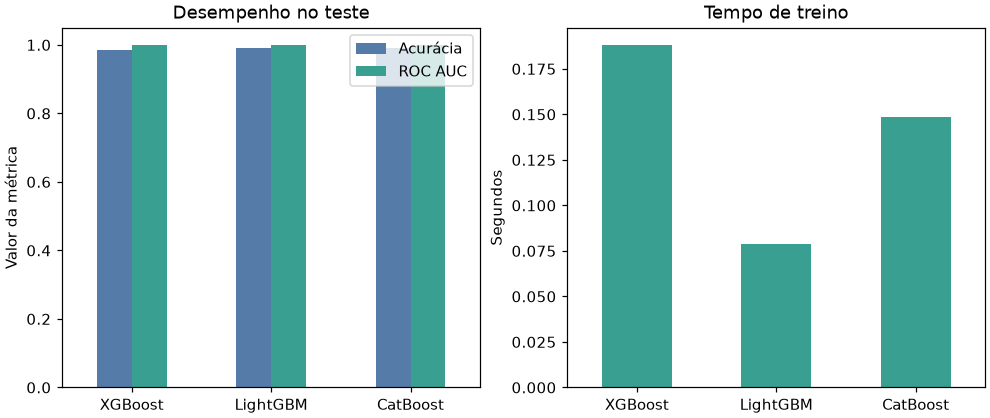

Versões usadas
numpy      2.5.4
pandas     3.1.1
sklearn    1.8.0
xgboost    3.4.1
lightgbm   4.7.0
catboost   1.2.10


In [6]:
fig, (ax_metricas, ax_tempo) = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
tabela_teste[["Acurácia", "ROC AUC"]].plot.bar(
    ax=ax_metricas, rot=0, color=["#557CA8", "#399F90"],
)
ax_metricas.set(title="Desempenho no teste", xlabel="", ylabel="Valor da métrica", ylim=(0, 1.05))
tabela_teste["Tempo (s)"].plot.bar(ax=ax_tempo, rot=0, color="#399F90")
ax_tempo.set(title="Tempo de treino", xlabel="", ylabel="Segundos")
plt.show()

print("Versões usadas")
for biblioteca in [np, pd, sklearn, xgboost, lightgbm, catboost]:
    print(f"{biblioteca.__name__:<10} {biblioteca.__version__}")

## Conclusão

No teste, **LightGBM e CatBoost acertaram 357 de 360 imagens (99,17%)**. O XGBoost acertou 355 (98,61%). As matrizes mostram que LightGBM e CatBoost tiveram a mesma contagem de erros por classe. O LightGBM teve **menor log loss** (0,0225), então as probabilidades que ele atribuiu aos rótulos corretos foram melhores segundo essa métrica.

O LightGBM também teve o menor tempo de treino nesta execução. Foi a configuração com taxa de aprendizado de 0,10 e até 15 folhas por árvore, escolhida pela AUC de validação. A diferença de acertos foi de apenas duas imagens e os resultados descrevem esta divisão da base de dígitos.
